# COMPAS verisinde sızıntısız model değerlendirme
## BIL545 Proje 1 · 9.16 Yeniden suç işleme risk skorları
**Üsküdar Üniversitesi · Bilgisayar Mühendisliği Yüksek Lisans · 2026–2027 Güz**  
**Ders:** Veri Madenciliğinde İleri Konular · **Öğretim üyesi:** Dr. Selma Güzel  
**Hazırlayan:** Yasin Göktepe · **Öğrenci no:** 264327007 · **Kapsam:** bireysel, temel Bölüm 1–3

**Araştırma sorusu:** Tarama anında bilinebilen özelliklerle iki yıllık yeniden suç kaydı vekili ne kadar öngörülebilir ve veri sızıntısı değerlendirmeyi nasıl değiştirir?

Bu çalışma ProPublica'nın COMPAS verisini denetler, Python modellerini dürüst bir değerlendirme protokolünde karşılaştırır ve Weka ile bağımsız kontrol yapar. Kurulan modeller COMPAS'ın kapalı algoritmasının kopyası değildir. Etiket gerçek suç davranışının doğrudan ölçümü değildir. Çalışma yalnız akademik inceleme içindir, kişi hakkında karar üretmez.

**Teslim esası:** 7 Ekim 2026 yönergesi ve şablonu, 29 Ekim Bölüm 3 uyarıları ve 4 Kasım teslim duyurusu birlikte kullanıldı. Son duyuruya göre 21 Kasım 2026 saat 23.59'a kadar GitHub deposuna teslim ve README'de erişilebilir video bağlantısı gerekir. Ayrı bir teslim raporu yoktur; bütün cevaplar bu defterdedir. Ek açıklama ve konuşma belgeleri öğrenme içindir.

## Hazırlık ve tekrarlanabilirlik
İlk kod hücresi tohumu sabitler ve sürümleri yazdırır. Paketler çalışma ortamında yoksa kurulurlar. scikit-learn ve mlxtend sürümleri sabittir. Google Colab'da **Çalışma Zamanı → Tümünü çalıştır** seçilir. İnternet ilk veri ve Weka indirmesinde gereklidir. Ham veri ve kişi düzeyindeki türetilmiş dosyalar GitHub'a eklenmez. Sonuç dosyaları `calisma_ciktilari/` altında yeniden üretilir.

In [20]:
import sys, subprocess, importlib.util, os
from importlib.metadata import version, PackageNotFoundError
os.environ.setdefault('OMP_NUM_THREADS','2')
for package,pinned in [('scikit-learn','1.6.1'),('mlxtend','0.25.0')]:
    try: installed=version(package)
    except PackageNotFoundError: installed=None
    if installed!=pinned:
        subprocess.check_call([sys.executable,'-m','pip','install','-q','--no-deps','--upgrade',package+'=='+pinned])
import numpy as np, pandas as pd, sklearn, matplotlib, scipy, mlxtend

from mlxtend.frequent_patterns import fpgrowth
from mlxtend.preprocessing import TransactionEncoder

# Colab altyapısından gelen bilinen utcnow uyarısını filtrele.
import warnings
warnings.filterwarnings(
    "ignore",
    message=r"datetime\.datetime\.utcnow\(\) is deprecated.*",
    category=DeprecationWarning,
    module=r"^jupyter_client\.session$",
)

from pathlib import Path
import hashlib, urllib.request, json, time, re, shutil, platform
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold,
    StratifiedKFold, cross_validate, cross_val_score, GridSearchCV)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (balanced_accuracy_score, roc_auc_score, f1_score,
    precision_score, recall_score, confusion_matrix, make_scorer)
from sklearn.inspection import permutation_importance
from scipy.stats import binomtest
SEED=42
np.random.seed(SEED)
N_JOBS=1
RUN=Path('calisma_ciktilari'); RUN.mkdir(exist_ok=True)
PRIVATE=RUN/'yerel_ozel'; PRIVATE.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi':110,'font.family':'DejaVu Sans','axes.spines.top':False,
    'axes.spines.right':False,'axes.titleweight':'bold','axes.labelsize':11})
for name,obj in [('Python',platform.python_version()),('numpy',np.__version__),
    ('pandas',pd.__version__),('scikit-learn',sklearn.__version__),
    ('scipy',scipy.__version__),('matplotlib',matplotlib.__version__),('mlxtend',mlxtend.__version__)]:
    print(f'{name:15s} {obj}')
print('Tohum:',SEED,'| Paralel iş:',N_JOBS)
assert sklearn.__version__=='1.6.1', 'Bu deney sklearn 1.6.1 ile doğrulandı. Sürümü kurup oturumu yeniden başlatın.'
assert mlxtend.__version__=='0.25.0', 'mlxtend==0.25.0 --no-deps kurup oturumu yeniden başlatın.'
RESULTS={}
def figure(fig, name, caption):
    fig.tight_layout()
    fig.savefig(RUN/(name+'.png'),dpi=160,bbox_inches='tight')
    display(fig); plt.close(fig)
    print('Şekil açıklaması:',caption)
def pm(a):
    a=np.asarray(a,dtype=float)
    return f'{a.mean():.4f} ± {a.std(ddof=1):.4f}'

Python          3.13.18
numpy           2.4.6
pandas          2.2.3
scikit-learn    1.6.1
scipy           1.16.3
matplotlib      3.10.0
mlxtend         0.25.0
Tohum: 42 | Paralel iş: 1


### Veriyi indirme ve bütünlük kontrolü
Kaynak dosya resmi ProPublica deposundan indirilir. SHA-256, kullanılan dosyanın değişmediğini kontrol eder. Yeniden çalıştırmada önceden indirilmiş dosya kullanılabilir. Açık erişim açık lisans anlamına gelmez; resmi depoda açık lisans beyanı doğrulanamadı. Dersin önerdiği veri olduğu için kaynak gösterilerek incelendi, ham veri yeniden dağıtılmadı.

In [21]:
DATA_URL='https://raw.githubusercontent.com/propublica/compas-analysis/master/compas-scores-two-years.csv'
EXPECTED_SHA='c451db85908b2f7fef1d83203bedf6b71ecda0d5af468d82ae62178f91d0cc7d'
cache=PRIVATE/'compas-scores-two-years.csv'
if not cache.exists(): urllib.request.urlretrieve(DATA_URL,cache)
sha=hashlib.sha256(cache.read_bytes()).hexdigest()
assert sha==EXPECTED_SHA, 'Kaynak dosya değişmiş. Yeni sürümü incelemeden sonuçlarla karıştırmayın.'
raw=pd.read_csv(cache,na_values=['','N/A','NA','NULL','?'])
print('Ham boyut:',raw.shape,'| SHA-256:',sha)
print('Kişi adları ve doğum tarihleri çıktı olarak gösterilmez.')
RESULTS['raw_shape']=list(raw.shape)

Ham boyut: (7214, 53) | SHA-256: c451db85908b2f7fef1d83203bedf6b71ecda0d5af468d82ae62178f91d0cc7d
Kişi adları ve doğum tarihleri çıktı olarak gösterilmez.


# Bölüm 1 Veri ön işleme ve sızıntı
**Makale okuma notu:** Kaufman vd. (2012), tahmin anında bulunmayan bilginin değerlendirme sürecine girmesini sızıntı olarak ele alır. Veriyi eğitim ve değerlendirme rollerine ayırmak, ön işleme istatistiklerini yalnız eğitimde öğrenmek gerekir. Bir sütunun güçlü ilişki göstermesi onun kullanılabilir olduğunu kanıtlamaz. Bu nedenle aşağıda önce tahmin anı ve izin verilen özellikler belirlenir; yanlış kurulumlar yalnız öğretici karşılaştırma olarak işaretlenir.

### 1.1 Veri künyesi ve tahmin anı
| Soru | Cevap |
|---|---|
| Toplayan ve amaç | ProPublica; Broward County Florida adli kayıtları ve COMPAS değerlendirmeleriyle risk skorlarını gazetecilik ve istatistiksel olarak incelemek |
| Dönem | 2013–2014 taramaları, 1 Nisan 2016'ya kadar incelenen takip kayıtları; dosyanın pozitif olay seçimine ilişkin sınırlama aşağıda ölçülür |
| Birim | Kanonik filtre sonrası tekil kişi kaydı; isim tek başına kişi anahtarı kabul edilmez |
| Hedef | `two_year_recid` 0/1; iki yıllık yeniden suç kaydı olarak oluşturulan, yeniden tutuklama/iddia ve kayıt sistemlerinden etkilenen vekil etiket |
| Temsil | Tek ABD ilçesi ve adalet sistemiyle temas etmiş, COMPAS kaydı eşleştirilebilen kişiler; tüm toplum, Türkiye ve kayda girmemiş davranışlar temsil edilmez |
| Lisans | Resmi depoda açık lisans doğrulanamadı. Kaynak bağlantısı verilir, ham veri depoya konmaz; yeniden dağıtım hakkı varsayılmaz |
| Tahmin anı | İndeks olayın COMPAS taraması sırasında bilinen temel demografi, geçmiş sayımları ve mevcut isnat bilgisi; kesin operasyonel erişim bu dosyadan doğrulanamaz |

ProPublica notebookundaki kanonik seçim uygulanır: tarama–tutuklama farkı ±30 gün, `is_recid != -1`, `c_charge_degree != O`, geçerli `score_text`. Bu seçim yeni popülasyona uygulanacak bir tahmin filtresi değildir; yayımlanan kohortun karşılaştırılabilir bir alt örneklemidir. `is_recid` sonucu model girdisine girmez.

In [22]:
eligible=(raw.days_b_screening_arrest.between(-30,30)
    & raw.is_recid.ne(-1) & raw.c_charge_degree.ne('O') & raw.score_text.notna())
df=raw.loc[eligible].copy().reset_index(drop=True)
assert len(df)==6172 and df.id.is_unique
person_key=df[['name','dob']].astype(str).agg('~'.join,axis=1)
assert person_key.is_unique, 'Tekrarlanan kişi bulundu; kişi temelli bölme gerekir.'
screen=pd.to_datetime(df.compas_screening_date)
dob=pd.to_datetime(df.dob)
df['age_at_screen']=(screen-dob).dt.days/365.2425
age_gap=df.age-np.floor(df.age_at_screen)
print('Kanonik kohort:',len(df),'| Elenen:',len(raw)-len(df))
print('ID ve isim+doğum tarihi anahtarı tekil:',df.id.is_unique,person_key.is_unique)
print('Ham age ile tarama yaşı farkı (yıl):',age_gap.describe().round(3).to_dict())
print('Türetilmiş yaş <18 kayıt:',int(df.age_at_screen.lt(18).sum()),'| Bu küçük grup otomatik silinmedi.')
cutoff=pd.Timestamp('2014-04-01')
late=screen>cutoff
time_audit=pd.crosstab(np.where(late,'2014-04-01 sonrası','2014-04-01 ve öncesi'),df.two_year_recid)
display(time_audit)
RESULTS['n']=len(df); RESULTS['age_gap_mean']=float(age_gap.mean())
RESULTS['time_audit']=time_audit.to_dict()

Kanonik kohort: 6172 | Elenen: 1042
ID ve isim+doğum tarihi anahtarı tekil: True True
Ham age ile tarama yaşı farkı (yıl): {'count': 6172.0, 'mean': 2.565, 'std': 0.65, 'min': 1.0, '25%': 2.0, '50%': 3.0, '75%': 3.0, 'max': 4.0}
Türetilmiş yaş <18 kayıt: 10 | Bu küçük grup otomatik silinmedi.


two_year_recid,0,1
row_0,,
2014-04-01 sonrası,0,868
2014-04-01 ve öncesi,3363,1941


**Yorum:** Filtre sonrasında 6172 kişi kaldı. `age` sütunundaki yaşın zaman referansı taramayla uyuşmuyor; bu nedenle `age_at_screen` türetildi, doğum tarihi girdilerden çıkarıldı. Türetilen yaş yaklaşık kesirli yıldır; 10 kayıtta 18'in altına düşer. Bu durum kaynak tarihlerini ayrıca denetleme gereğini gösterir; belgesiz bir erişkinlik filtresi eklenmedi. Yaş dilimi bu nedenle “25 altı” diye adlandırıldı. Tarih kesiminden sonraki 868 kaydın tamamında hedefin 1 olması örneklem seçimi sorunudur. Barenstein (2019) bu veri oluşturma problemine dikkat çeker. Tarama yılı/ayı modele alınmaz ve 2.5'te dönem duyarlılığı raporlanır. Sonuçlar bu kohort için geçerlidir; ileriye dönük risk veya evrensel adillik kanıtı değildir.

### 1.2 Keşifsel analiz ve özellik denetimi
Ham dosyanın tamamı için saklama tipi, ölçek tipi, eksiklik, sıfır oranı ve farklı değer sayısı gösterilir. Sayı biçimindeki ID'ler ölçüm sayılmaz. Veri sızıntısını önlemek için sekiz özellikten oluşan izin listesi kullanılır. `race` yalnız denetim ve küp boyutu olarak korunur; modele girmez. `sex` modele girer ve hassas özellik olduğu açıkça belirtilir. Bu seçim tek başına adillik sağlamaz.

,saklama_tipi,olcek,eksik_orani,farkli_deger,sifir_orani
id,int64,kimlik / nominal,0.0000,7214,0.0000
name,object,kimlik / nominal,0.0000,7158,0.0000
first,object,kimlik / nominal,0.0000,2800,0.0000
last,object,kimlik / nominal,0.0000,3950,0.0000
compas_screening_date,object,zaman,0.0000,690,0.0000
sex,object,nominal,0.0000,2,0.0000
dob,object,kimlik / nominal,0.0000,5452,0.0000
age,int64,oran / sayım,0.0000,65,0.0000
age_cat,object,sıralı,0.0000,3,0.0000
race,object,nominal,0.0000,6,0.0000


Tam yinelenen satır: 0
Yinelenen .1 sütunlar eşit: True True


,adet,oran
hedef,,
0,3363,0.54488
1,2809,0.45512


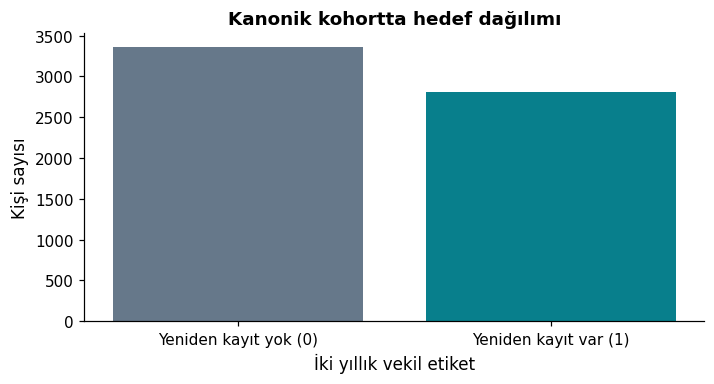

Şekil açıklaması: Sınıflar yaklaşık dengeli olsa da sınıf başına duyarlılığı eşit ağırlayan balanced accuracy temel ölçüttür.
Geliştirme: 4937 | Ayrılmış nihai test: 1235 | ÇD: 15 kat değerlendirmesi


In [23]:
def scale_type(col):
    if col in ['id','name','first','last','dob'] or 'case_number' in col: return 'kimlik / nominal'
    if 'date' in col or col in ['c_jail_in','c_jail_out','r_jail_in','r_jail_out','in_custody','out_custody']: return 'zaman'
    if 'decile' in col or col=='age_cat': return 'sıralı'
    if raw[col].dtype=='object' or str(raw[col].dtype)=='str': return 'nominal'
    if col in ['two_year_recid','is_recid','event','is_violent_recid','violent_recid']: return 'ikili / etiket'
    return 'oran / sayım'
audit=pd.DataFrame({'saklama_tipi':raw.dtypes.astype(str),'olcek':[scale_type(c) for c in raw],
    'eksik_orani':raw.isna().mean(),'farkli_deger':raw.nunique(),
    'sifir_orani':[(raw[c].eq(0)).mean() for c in raw]})
display(audit.round(4))
audit.to_csv(RUN/'ozellik_denetimi.csv',index_label='ozellik')
print('Tam yinelenen satır:',raw.duplicated().sum())
print('Yinelenen .1 sütunlar eşit:',df['decile_score'].equals(df['decile_score.1']),df['priors_count'].equals(df['priors_count.1']))
NUM=['age_at_screen','juv_fel_count','juv_misd_count','juv_other_count','priors_count']
LOW=['sex','c_charge_degree']; HIGH=['c_charge_desc']; FEATURES=NUM+LOW+HIGH
X=df[FEATURES].copy(); y=df.two_year_recid.astype(int)
# Pandas'ın StringDtype/pd.NA değerlerini sklearn için object/np.nan yap.
for c in LOW+HIGH: X[c]=X[c].astype(object).where(X[c].notna(),np.nan)
display(y.value_counts().rename_axis('hedef').to_frame('adet').assign(oran=lambda t:t.adet/len(y)))
fig,ax=plt.subplots(figsize=(6.6,3.6))
ax.bar(['Yeniden kayıt yok (0)','Yeniden kayıt var (1)'],y.value_counts().sort_index(),color=['#66788a','#087f8c'])
ax.set(xlabel='İki yıllık vekil etiket',ylabel='Kişi sayısı',title='Kanonik kohortta hedef dağılımı')
figure(fig,'hedef_dagilimi','Sınıflar yaklaşık dengeli olsa da sınıf başına duyarlılığı eşit ağırlayan balanced accuracy temel ölçüttür.')
dev_idx,test_idx=train_test_split(np.arange(len(df)),test_size=.20,stratify=y,random_state=SEED)
X_dev,X_test=X.iloc[dev_idx].copy(),X.iloc[test_idx].copy()
y_dev,y_test=y.iloc[dev_idx].copy(),y.iloc[test_idx].copy()
cv=RepeatedStratifiedKFold(n_splits=5,n_repeats=3,random_state=SEED)
SPLITS=list(cv.split(X_dev,y_dev))
print('Geliştirme:',len(dev_idx),'| Ayrılmış nihai test:',len(test_idx),'| ÇD:',len(SPLITS),'kat değerlendirmesi')

**Yorum:** Kaynak 7214 × 53 boyutundadır ve sayısal/kategorik alanları birlikte içerir. `c_charge_desc` kanonik kohortta 389 farklı değerle yüksek kardinalitelidir. Tam yinelenen satır sayısı 0'dır; aynı isimler tek başına aynı kişi kabul edilmemiştir. “En az 10 özellik” koşulu kaynak veri seçimine aittir; sızıntılı alanları tutarak sayı tamamlanmaz. 4937 geliştirme kaydı model seçimi ve deneyler için, 1235 test kaydı ise model seçimi tamamlandıktan sonraki tek değerlendirme için ayrıldı. EDA'da yalnız toplu hedef bilgisi görülür; test skorları seçimde kullanılmaz.

| Şüpheli alan grubu | Karar ve gerekçe |
|---|---|
| name, first, last, dob, id, dava numaraları | Doğrudan veya dolaylı kimlik. Modelden ve çıktı tablolarından çıkarıldı |
| r_*, vr_*, is_recid, is_violent_recid, event, start, end, in_custody, out_custody | Sonuç veya takip süreciyle ilişkili. Gelecek bilgi ve gözlem süresi sızıntısı riski |
| c_jail_out, c_jail_in | Çıkışların bir bölümü taramadan sonra; operasyonel zaman belirsizliği nedeniyle ikisi de çıkarıldı |
| decile_score, score_text ve v_* skorları | İncelenen mevcut sistemin çıktıları. Bağımsız yeni modelin girdisine alınmadı |
| age, age_cat ve .1 kopyaları | Zaman referansı veya yinelenme. Yeniden hesaplanan yaş kullanıldı |
| screening ve olay tarihleri, days_b_screening_arrest | Filtre/denetim veya yaş türetimi için kullanıldı; seçim mekanizmasını öğrenme riskiyle modelden çıkarıldı |

### 1.3 Eksiklik analizi
Kodlanmış eksikler okuma sırasında NaN'a dönüştürüldü. Tamamen boş `violent_recid` ayrı bir şema sorunudur. Sonuç alanlarındaki yapısal eksiklik model girdisi olamaz. `add_indicator` deneyi yalnız tahmin anında kullanılabilir X alanlarında ve aynı geliştirme katlarında yapılır.

,eksik_orani
violent_recid,1.000000
vr_charge_degree,0.887881
vr_offense_date,0.887881
vr_case_number,0.887881
vr_charge_desc,0.887881
c_arrest_date,0.872975
r_jail_in,0.676442
r_days_from_arrest,0.676442
r_jail_out,0.676442
r_charge_desc,0.523007


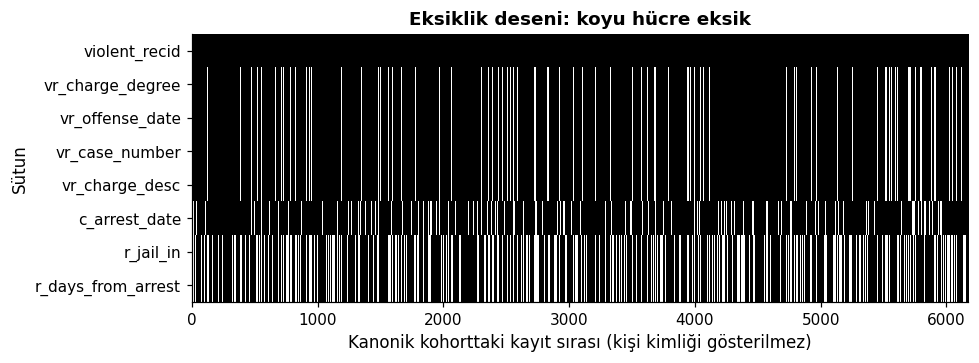

Şekil açıklaması: Sonuç ve takip alanlarındaki eksiklikler gelişigüzel bir sensör kaybı gibi yorumlanamaz.


vr_case_number,Dolu,Eksik
is_violent_recid,,
0,0.0,1.0
1,1.0,0.0


c_charge_desc eksik: 5


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

,Kurulum,BA ortalama ± std
0,Gösterge yok,0.6616 ± 0.0168
1,add_indicator,0.6617 ± 0.0166


In [24]:
missing=df.drop(columns='age_at_screen').isna().mean().sort_values(ascending=False)
display(missing.head(12).to_frame('eksik_orani'))
top_missing=list(missing.head(8).index)
fig,ax=plt.subplots(figsize=(9,3.4))
ax.imshow(df[top_missing].isna().to_numpy().T,aspect='auto',interpolation='nearest',cmap='Greys',vmin=0,vmax=1)
ax.set_yticks(range(len(top_missing)),top_missing)
ax.set(xlabel='Kanonik kohorttaki kayıt sırası (kişi kimliği gösterilmez)',ylabel='Sütun',title='Eksiklik deseni: koyu hücre eksik')
figure(fig,'eksiklik_deseni','Sonuç ve takip alanlarındaki eksiklikler gelişigüzel bir sensör kaybı gibi yorumlanamaz.')
display(pd.crosstab(df.is_violent_recid,df.vr_case_number.isna(),normalize='index').rename(columns={False:'Dolu',True:'Eksik'}))
print('c_charge_desc eksik:',int(X.c_charge_desc.isna().sum()))
def make_pre(encoding='rare',indicator=False):
    num=Pipeline([('impute',SimpleImputer(strategy='median',add_indicator=indicator)),('scale',StandardScaler())])
    low=Pipeline([('impute',SimpleImputer(strategy='most_frequent',add_indicator=indicator)),
        ('ohe',OneHotEncoder(handle_unknown='ignore',sparse_output=False))])
    if encoding=='target':
        charge=Pipeline([('impute',SimpleImputer(strategy='constant',fill_value='Eksik')),
            ('encode',TargetEncoder(target_type='binary',smooth='auto',cv=5,shuffle=True,random_state=SEED))])
    else:
        charge=Pipeline([('impute',SimpleImputer(strategy='constant',fill_value='Eksik',add_indicator=indicator)),
            ('encode',OneHotEncoder(handle_unknown='ignore',sparse_output=False,
                min_frequency=20 if encoding=='rare' else None))])
    return ColumnTransformer([('num',num,NUM),('low',low,LOW),('charge',charge,HIGH)],sparse_threshold=0)
def make_pipe(model,encoding='rare',indicator=False):
    return Pipeline([('pre',make_pre(encoding,indicator)),('model',clone(model))])
lr=LogisticRegression(max_iter=1500,C=1,random_state=SEED)
indicator_scores={str(flag):cross_val_score(make_pipe(lr,indicator=flag),X_dev,y_dev,cv=SPLITS,
    scoring='balanced_accuracy',n_jobs=N_JOBS) for flag in [False,True]}
display(pd.DataFrame({'Kurulum':['Gösterge yok','add_indicator'],
    'BA ortalama ± std':[pm(indicator_scores['False']),pm(indicator_scores['True'])]}))

**Yorum:** En çok eksik `violent_recid` alanı tamamen boştur. Bu sütunda gözlenen değer olmadığı için MCAR/MAR/MNAR ayrımı veriden tanımlanamaz; şema/boş yer tutucu açıklaması makuldür ve imputasyonla anlamlı bilgi üretilemez. İkinci en yüksek oranı paylaşan `vr_*` alanlarında (örneğin `vr_case_number`) eksiklik, şiddet içeren yeniden olayın bulunmamasıyla bağlantılıdır. Olay göstergesi gözlenmiş kabul edildiğinde yapısal/MAR benzeri açıklama savunulabilir, ancak gözlenmemiş kayıt süreçlerine bağlı MNAR olasılığı dışlanamaz. Bunlar mekanizma kanıtı değildir. `c_arrest_date` ve `c_offense_date` tamamlayıcı kayıt biçimleri de basit MCAR iddiasını zayıflatır. `r_days_from_arrest` alanında -1 kodu olan 5 ham kayıt vardır; bu sonuç alanı kullanılmaz. Bütün negatifler eksik sayılmaz: `days_b_screening_arrest` için negatif günler geçerlidir.

Gösterge yokken BA 0.6616 ± 0.0168, göstergeyle 0.6617 ± 0.0166. Güvenli girdilerde eksiklik az olduğu için büyük bir fark beklenmez. Sonuç alanlarının eksiklik göstergelerini modele eklemek, olayın varlığını sızdırırdı.

### 1.4 Yüksek kardinaliteli kategorik kodlama
Aynı lojistik model ve aynı katlar üzerinde normal bire-bir (OHE), nadirleri birleştiren OHE ve kat dışı hedef kodlama karşılaştırılır. Nadir eşik 20 eğitim kaydıdır ve her katın içinde öğrenilir. `TargetEncoder.fit_transform` eğitim kayıtlarını iç 5 kat ile çapraz kodlar; doğrulama kayıtlarının etiketleri kodlamaya girmez.

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

,Kodlama,BA ortalama ± std
0,onehot,0.6562 ± 0.0140
1,rare,0.6616 ± 0.0168
2,target,0.6575 ± 0.0187
3,YANLIS_global_target,0.6857 ± 0.0147


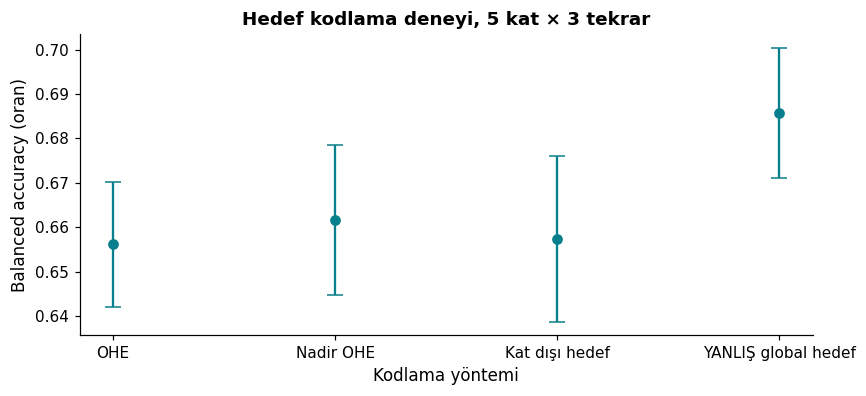

Şekil açıklaması: Çubuklar katlar arasındaki standart sapmadır, güven aralığı değildir; yanlış kurulumun skoru geçerli genelleme başarımı değildir.


In [25]:
encoding_scores={}
for enc in ['onehot','rare','target']:
    encoding_scores[enc]=cross_val_score(make_pipe(lr,encoding=enc),X_dev,y_dev,
        cv=SPLITS,scoring='balanced_accuracy',n_jobs=N_JOBS)
# BİLEREK YANLIŞ: geliştirme verisinin tüm etiketleriyle kategori ortalaması öğrenilir.
charge_values=X_dev[HIGH].fillna('Eksik')
bad_encoder=TargetEncoder(target_type='binary',smooth='auto',random_state=SEED)
bad_encoded=bad_encoder.fit(charge_values,y_dev).transform(charge_values)
X_bad=X_dev[NUM+LOW].copy(); X_bad['charge_target_leaked']=bad_encoded[:,0]
bad_pre=ColumnTransformer([
    ('num',Pipeline([('fill',SimpleImputer()),('scale',StandardScaler())]),NUM+['charge_target_leaked']),
    ('cat',OneHotEncoder(handle_unknown='ignore',sparse_output=False),LOW)])
encoding_scores['YANLIS_global_target']=cross_val_score(Pipeline([('pre',bad_pre),('model',clone(lr))]),
    X_bad,y_dev,cv=SPLITS,scoring='balanced_accuracy',n_jobs=N_JOBS)
display(pd.DataFrame({'Kodlama':list(encoding_scores),'BA ortalama ± std':[pm(v) for v in encoding_scores.values()]}))
fig,ax=plt.subplots(figsize=(8,3.7))
labels=['OHE','Nadir OHE','Kat dışı hedef','YANLIŞ global hedef']
ax.errorbar(range(4),[v.mean() for v in encoding_scores.values()],
    yerr=[v.std(ddof=1) for v in encoding_scores.values()],fmt='o',capsize=5,color='#087f8c')
ax.set_xticks(range(4),labels); ax.set(xlabel='Kodlama yöntemi',ylabel='Balanced accuracy (oran)',title='Hedef kodlama deneyi, 5 kat × 3 tekrar')
figure(fig,'kodlama_karsilastirma','Çubuklar katlar arasındaki standart sapmadır, güven aralığı değildir; yanlış kurulumun skoru geçerli genelleme başarımı değildir.')

**Yorum:** Normal OHE 0.6562 ± 0.0140, nadir OHE 0.6616 ± 0.0168, doğru hedef kodlama 0.6575 ± 0.0187, yanlış global hedef kodlama 0.6857 ± 0.0147 verdi. Yanlış yöntemde kişinin hedefi kendi kategori değerine etki eder; nadir kategorilerde sorun belirginleşir. Ana karşılaştırmada yorumlanabilir, hedef bilgisinden bağımsız nadir OHE önceden sabitlendi. Kodlama deneyindeki skorlar daha sonra yöntem seçip tekrar aynı katları “bağımsız test” diye sunmak için kullanılmaz.

### 1.5 Ayrı global ön işleme sızıntısı deneyi
Bu deney 1.4'teki hedef kodlama deneyinden ayrıdır. Aynı 15 katta, doldurma/ölçekleme/nadir kategori gruplamasını bütün geliştirme verisinde öğrenmek ile her eğitim katında öğrenmek karşılaştırılır. Model her iki durumda yalnız katın eğitim etiketlerini görür.

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

,Kurulum,BA ortalama ± std
0,Doğru kat içi Pipeline,0.6616 ± 0.0168
1,YANLIŞ global ön işleme,0.6588 ± 0.0173


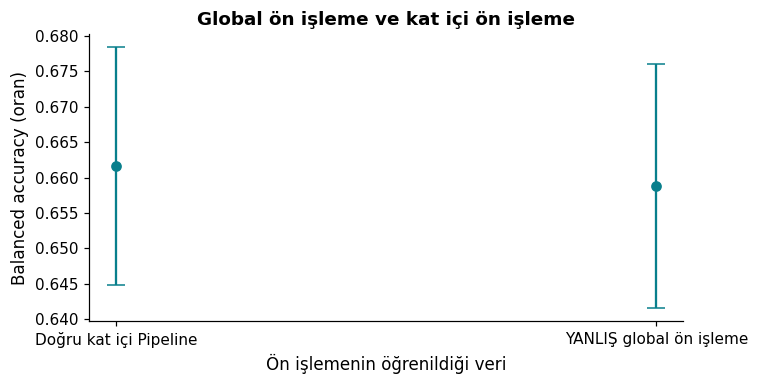

Şekil açıklaması: Gözlenen farkın küçük olması global ön işleme yöntemini geçerli yapmaz.


In [26]:
global_pre=make_pre('rare')
global_values=global_pre.fit_transform(X_dev,y_dev)  # BİLEREK YANLIŞ: doğrulama X dağılımı görülüyor.
leak_scores={
    'Doğru kat içi Pipeline':encoding_scores['rare'],
    'YANLIŞ global ön işleme':cross_val_score(clone(lr),global_values,y_dev,cv=SPLITS,
        scoring='balanced_accuracy',n_jobs=N_JOBS)}
display(pd.DataFrame({'Kurulum':list(leak_scores),'BA ortalama ± std':[pm(v) for v in leak_scores.values()]}))
fig,ax=plt.subplots(figsize=(7,3.6))
ax.errorbar(range(2),[v.mean() for v in leak_scores.values()],yerr=[v.std(ddof=1) for v in leak_scores.values()],fmt='o',capsize=6,color='#087f8c')
ax.set_xticks(range(2),list(leak_scores)); ax.set(xlabel='Ön işlemenin öğrenildiği veri',ylabel='Balanced accuracy (oran)',title='Global ön işleme ve kat içi ön işleme')
figure(fig,'on_isleme_sizintisi','Gözlenen farkın küçük olması global ön işleme yöntemini geçerli yapmaz.')

**Yorum:** Doğru kurulum 0.6616 ± 0.0168, yanlış kurulum 0.6588 ± 0.0173. Ortalama fark -0.0028. Etiketsiz ön işleme sızıntısı her deneyde büyük veya pozitif bir fark üretmek zorunda değildir. Kaynaklarda tanımlanan ayrım prosedüre ilişkindir; küçük fark sızıntının yokluğunu kanıtlamaz. Yanlış nesneler final modele aktarılmaz.

### 1.6 Baseline ve ilk model
DummyClassifier çoğunluk sınıfını tahmin eder. Basit model lojistik regresyondur. Tüm geçerli değerlendirmeler ortak 5 kat × 3 tekrar katmanlı çapraz doğrulama katlarını kullanır. Ölçütler oran cinsindedir. Katlar örtüştüğü için ortalama ± standart sapma, bağımsız 15 deney veya %95 güven aralığı anlamına gelmez.

In [27]:
dummy=DummyClassifier(strategy='most_frequent')
baseline_scores=cross_val_score(make_pipe(dummy),X_dev,y_dev,cv=SPLITS,scoring='balanced_accuracy',n_jobs=N_JOBS)
display(pd.DataFrame({'Model':['Dummy çoğunluk','Lojistik regresyon'],
    'BA ortalama ± std':[pm(baseline_scores),pm(encoding_scores['rare'])]}))

,Model,BA ortalama ± std
0,Dummy çoğunluk,0.5000 ± 0.0000
1,Lojistik regresyon,0.6616 ± 0.0168


**Yorum:** Baseline BA 0.5000 ± 0.0000 iken lojistik regresyon 0.6616 ± 0.0168 verdi. Çoğunluğu tahmin etmenin balanced accuracy değeri iki sınıf bulunduğunda 0.5'tir. Accuracy ikincil Weka tutarlılık kontrolünde görülebilir; ana seçim BA ile yapılır.

### 1.7 Weka ile gerçek bağımsız kontrol
Aynı geliştirme kayıtları, aynı sekiz girdiden oluşan ARFF'e dönüştürülür. Ham isim/doğum tarihi yazılmaz. Weka 3.8.6 ZeroR ve J48, 10 kat ve tohum 42 ile çalışır. Weka ve sklearn kat atamaları birebir aynı değildir. J48 C4.5, sklearn ağacı CART olduğu için tam eşit skor beklenmez. Bu kontrol ayrı uygulama üzerinde genel tutarlılığı sınar.

In [28]:
def arff_quote(v):
    return "'"+str(v).replace('\\','\\\\').replace("'","\\'")+"'"
def write_arff(table,path,relation,numeric=()):
    lines=['@relation '+arff_quote(relation),'']
    for c in table:
        if c in numeric: spec='numeric'
        else: spec='{'+','.join(arff_quote(v) for v in sorted(table[c].dropna().astype(str).unique()))+'}'
        lines.append('@attribute '+arff_quote(c)+' '+spec)
    lines.extend(['','@data'])
    for row in table.itertuples(index=False,name=None):
        lines.append(','.join('?' if pd.isna(v) else (str(float(v)) if c in numeric else arff_quote(v)) for c,v in zip(table.columns,row)))
    path.write_text('\n'.join(lines),encoding='utf-8')
WEKA=PRIVATE/'weka'; WEKA.mkdir(exist_ok=True)
jar=WEKA/'weka-stable-3.8.6.jar'; bounce=WEKA/'bounce-0.18.jar'
for path,url,digest in [
    (jar,'https://repo.maven.apache.org/maven2/nz/ac/waikato/cms/weka/weka-stable/3.8.6/weka-stable-3.8.6.jar','932ea2f342b58fe45736389e9c426d5b5955e610d1f5f6485117f532068915e9'),
    (bounce,'https://repo.maven.apache.org/maven2/nz/ac/waikato/cms/weka/thirdparty/bounce/0.18/bounce-0.18.jar','bffff1505335c02256b7ab2ccffbe4aa4d3ac9fe14c17557809b7c9d99d666ca')]:
    if not path.exists(): urllib.request.urlretrieve(url,path)
    assert hashlib.sha256(path.read_bytes()).hexdigest()==digest
java=shutil.which('java')
if platform.system()=='Windows' and Path(r'C:\Program Files (x86)\Java\jre1.8.0_511\bin\java.exe').exists():
    java=r'C:\Program Files (x86)\Java\jre1.8.0_511\bin\java.exe'
assert java, 'Weka kontrolü için Java gerekli. Colab ortamında Java bulunur.'
java_cmd=[java,'-Xmx768m','-Djava.awt.headless=true','-DWEKA_HOME='+str(WEKA.resolve()),'-cp',os.pathsep.join([str(jar),str(bounce)])]
weka_table=X_dev.copy(); weka_table['target']=y_dev.astype(str)
class_arff=PRIVATE/'compas_gelistirme.arff'
write_arff(weka_table,class_arff,'compas_development',numeric=NUM)
weka_class={}
for title,cls in [('ZeroR','weka.classifiers.rules.ZeroR'),('J48','weka.classifiers.trees.J48')]:
    command=java_cmd+[cls,'-t',str(class_arff),'-c','last','-x','10','-s',str(SEED)]
    result=subprocess.run(command,capture_output=True,text=True,encoding='utf-8',errors='replace',timeout=180)
    assert result.returncode==0 and 'Stratified cross-validation' in result.stdout, result.stderr+result.stdout
    weka_class[title]=result.stdout
    (RUN/f'weka_{title}.txt').write_text(result.stdout,encoding='utf-8')
    print('\nWeka',title,'komutu:', ' '.join(command[6:])); print(result.stdout)
cv10=StratifiedKFold(n_splits=10,shuffle=True,random_state=SEED)
python10={}
for title,model in [('Dummy',dummy),('CART',DecisionTreeClassifier(random_state=SEED))]:
    score=cross_validate(make_pipe(model,encoding='onehot'),X_dev,y_dev,cv=cv10,
        scoring={'ba':'balanced_accuracy','acc':'accuracy'},n_jobs=N_JOBS)
    python10[title]=score
display(pd.DataFrame([{'Python model':k,'BA':pm(v['test_ba']),'Accuracy':pm(v['test_acc'])} for k,v in python10.items()]))
weka_metrics={}
for title,output in weka_class.items():
    cv_output=output.split('=== Stratified cross-validation ===')[-1]
    matrix_rows=re.findall(r'^\s*(\d+)\s+(\d+)\s+\|\s+[ab]\s*=',cv_output,re.M)
    matrix=np.array(matrix_rows[-2:],dtype=int)
    assert matrix.shape==(2,2)
    weka_metrics[title]={'accuracy':float(np.trace(matrix)/matrix.sum()),
        'ba':float(np.mean(np.diag(matrix)/matrix.sum(axis=1))),'confusion':matrix.tolist()}
display(pd.DataFrame(weka_metrics).T)
RESULTS['weka_classification']=weka_metrics


Weka ZeroR komutu: weka.classifiers.rules.ZeroR -t calisma_ciktilari/yerel_ozel/compas_gelistirme.arff -c last -x 10 -s 42
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate

=== Classifier model (full training set) ===

ZeroR predicts class value: 0

Time taken to build model: 0.06 seconds

Time taken to test model on training data: 0.08 seconds

=== Error on training data ===

Correctly Classified Instances        2690               54.4865 %
Incorrectly Classified Instances      2247               45.5135 %
Kappa statistic                          0     
Mean absolute error                      0.496 
Root mean squared error                  0.498 
Relative absolute error                100      %
Root relati

,Python model,BA,Accuracy
0,Dummy,0.5000 ± 0.0000,0.5449 ± 0.0005
1,CART,0.6129 ± 0.0235,0.6168 ± 0.0232


,accuracy,ba,confusion
ZeroR,0.544865,0.5,"[[2690, 0], [2247, 0]]"
J48,0.659915,0.657686,"[[1836, 854], [825, 1422]]"


**Yorum:** Yukarıdaki çıktı gerçek Java/Weka çalıştırmasının standart çıktısıdır. ZeroR accuracy 0.5449 ve BA 0.5000; Python Dummy accuracy 0.5449 ± 0.0005 ve BA 0.5000 ± 0.0000 ile tutarlıdır. J48 BA 0.6577, Python CART 0.6129 ± 0.0235 verdi. J48'in budaması ile sınırsız CART'ın karmaşıklığı farklıdır; ayrıca algoritma, eksik/kategorik değer işleyişi ve katlar farklıdır. Bu farkı sızıntı veya uygulama hatası olarak tek başına yorumlamak doğru olmaz. Weka'nın toplu 10 kat sonucu tek gözlemdir; model sıralaması için tekrarlı Python değerlendirmesi kullanılır. Weka çıktısındaki eğitim skoru çapraz doğrulama skoru ile karıştırılmaz. Kullanılmayan lineer cebir eklentisine ait `mtj` uyarısı bu Weka algoritmalarının çalışmasını engellememiştir.

# Bölüm 2 Sınıflandırma ve dürüst değerlendirme
**Makale okuma notu:** Dietterich (1998), aynı veri üzerinde karşılaştırılan algoritmaların hata tahminlerinin bağımlılığına dikkat çeker. Çapraz doğrulama kat skorlarına bağımsız örneklemlermiş gibi sıradan t testi uygulamak uygun değildir. Bu projede model seçimi geliştirme verisinde tamamlanır, sonra iki modelin aynı ayrılmış test kayıtlarındaki hataları exact McNemar testiyle karşılaştırılır. Anlamsız sonuç eşitlik kanıtı değildir; etki büyüklüğü ve test örneklemiyle birlikte yorumlanır.

### 2.1 Model karşılaştırması
Önceden belirlenen ana ölçüt **balanced accuracy** = (duyarlılık + özgüllük) / 2'dir. ROC-AUC eşikten bağımsız sıralama ölçüsü, F1/precision/recall pozitif sınıfı açıklayan ikincil ölçütlerdir. Pozitif sınıf `two_year_recid=1`'dir. Modeller aynı katlar ve aynı nadir OHE hattını kullanır. Sınıf dengeleme/SMOTE yapılmaz; sınıflar yaklaşık dengelidir. Bu modeller adli karar için optimize edilmez.

Dummy 0.5000 ± 0.0000


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

Lojistik 0.6616 ± 0.0168
Karar ağacı 0.6559 ± 0.0199
k-NN 0.6433 ± 0.0143
Rastgele orman 0.6607 ± 0.0193
Gradyan artırma 0.6632 ± 0.0175


,ba,auc,f1,precision,recall,süre_s
Model,,,,,,
Gradyan artırma,0.6632 ± 0.0175,0.7246 ± 0.0165,0.6161 ± 0.0243,0.6554 ± 0.0187,0.5820 ± 0.0351,5.8
Lojistik,0.6616 ± 0.0168,0.7257 ± 0.0168,0.6020 ± 0.0225,0.6723 ± 0.0208,0.5453 ± 0.0275,1.4
Rastgele orman,0.6607 ± 0.0193,0.7308 ± 0.0189,0.6017 ± 0.0279,0.6690 ± 0.0204,0.5474 ± 0.0366,8.1
Karar ağacı,0.6559 ± 0.0199,0.7109 ± 0.0210,0.6061 ± 0.0357,0.6485 ± 0.0250,0.5731 ± 0.0654,0.9
k-NN,0.6433 ± 0.0143,0.6973 ± 0.0156,0.6013 ± 0.0195,0.6216 ± 0.0146,0.5827 ± 0.0275,1.8
Dummy,0.5000 ± 0.0000,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.8


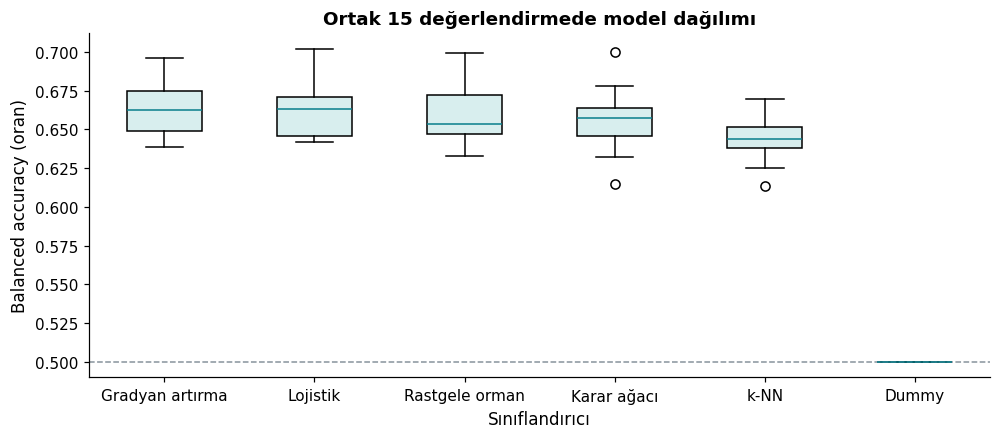

Şekil açıklaması: Kutular 5 kat × 3 tekrar skorlarını gösterir; katlar bağımsız deney değildir.


In [29]:
MODELS={
    'Dummy':dummy,
    'Lojistik':lr,
    'Karar ağacı':DecisionTreeClassifier(max_depth=5,min_samples_leaf=25,random_state=SEED),
    'k-NN':KNeighborsClassifier(n_neighbors=31,weights='distance',n_jobs=1),
    'Rastgele orman':RandomForestClassifier(n_estimators=160,min_samples_leaf=10,max_features='sqrt',random_state=SEED,n_jobs=1),
    'Gradyan artırma':HistGradientBoostingClassifier(max_iter=120,max_leaf_nodes=15,l2_regularization=2,random_state=SEED)}
SCORING={'ba':'balanced_accuracy','auc':'roc_auc','f1':'f1',
    'precision':make_scorer(precision_score,zero_division=0),'recall':'recall'}
scores={}; rows=[]
for title,model in MODELS.items():
    tic=time.perf_counter()
    score=cross_validate(make_pipe(model),X_dev,y_dev,cv=SPLITS,scoring=SCORING,n_jobs=N_JOBS,error_score='raise')
    scores[title]=score
    rows.append({'Model':title,**{m:pm(score['test_'+m]) for m in SCORING},'süre_s':round(time.perf_counter()-tic,1)})
    print(title,pm(score['test_ba']),flush=True)
summary=pd.DataFrame(rows).set_index('Model')
ranking=sorted(scores,key=lambda n:scores[n]['test_ba'].mean(),reverse=True)
display(summary.loc[ranking])
summary.to_csv(RUN/'model_karsilastirma.csv')
fold_table=pd.concat([pd.DataFrame({'model':name,'kat':range(1,16),**{m:res['test_'+m] for m in SCORING}}) for name,res in scores.items()],ignore_index=True)
fold_table.to_csv(RUN/'kat_skorlari.csv',index=False)
fig,ax=plt.subplots(figsize=(9.2,4.1))
ax.boxplot([scores[n]['test_ba'] for n in ranking],tick_labels=ranking,patch_artist=True,
    boxprops={'facecolor':'#d8eeee'},medianprops={'color':'#087f8c'})
ax.axhline(.5,color='#88939d',linestyle='--',linewidth=1)
ax.set(xlabel='Sınıflandırıcı',ylabel='Balanced accuracy (oran)',title='Ortak 15 değerlendirmede model dağılımı')
figure(fig,'model_karsilastirma','Kutular 5 kat × 3 tekrar skorlarını gösterir; katlar bağımsız deney değildir.')
RESULTS['models']={n:{m:{'mean':float(s['test_'+m].mean()),'std':float(s['test_'+m].std(ddof=1))} for m in SCORING} for n,s in scores.items()}
RESULTS['ranking']=ranking

**Yorum:** Geliştirme çapraz doğrulamasında en yüksek ortalama BA Gradyan artırma için 0.6632 ± 0.0175; ikinci model Lojistik için 0.6616 ± 0.0168 bulundu. Seçim bu aşamada sabitlendi. Standart sapma kat/tekrar değişkenliğini gösterir. Dummy pozitif tahmin üretmediği için precision matematiksel olarak tanımsızdır; tabloda `zero_division=0` raporlama uzlaşımıyla 0 gösterildi. Tek en yüksek katı seçmek veya ROC-AUC ile BA sıralamasını sonuç görüldükten sonra değiştirmek yapılmadı. Parametreler sınırlı karmaşıklık ve açıklanabilirlik amacıyla sabitlendi; ana sonuçlar kapsamlı hiperparametre aramasının sonucu değildir.

### 2.2 Karar ağacının yorumu
Ağaç geliştirme verisinin tamamında yalnız yorum amacıyla eğitilir. Aşağıdaki kök ve ilk iki düzey bölmeleri, ham sayımların StandardScaler ölçeğinden geri çevrilmesiyle alan bilgisiyle yorumlanır. Bu metin ağacı bağımsız test skoru değildir.

In [30]:
tree_pipe=make_pipe(MODELS['Karar ağacı']).fit(X_dev,y_dev)
tree_names=tree_pipe.named_steps['pre'].get_feature_names_out()
tree_rules=export_text(tree_pipe.named_steps['model'],feature_names=list(tree_names),max_depth=2,decimals=3)
print(tree_rules)
tree=tree_pipe.named_steps['model'].tree_
scale=tree_pipe.named_steps['pre'].named_transformers_['num'].named_steps['scale']
tree_nodes=[]
def visit(node,depth=0):
    if depth>2 or tree.feature[node]<0: return
    i=tree.feature[node]; name=tree_names[i]; threshold=tree.threshold[node]
    raw_threshold=float(threshold*scale.scale_[i]+scale.mean_[i]) if i<len(NUM) else float(threshold)
    tree_nodes.append({'derinlik':depth,'ozellik':name,'ham_esik':round(raw_threshold,3),'kayit':int(tree.n_node_samples[node])})
    visit(tree.children_left[node],depth+1);visit(tree.children_right[node],depth+1)
visit(0)
display(pd.DataFrame(tree_nodes))
RESULTS['tree_nodes']=tree_nodes

|--- num__priors_count <= -0.161
|   |--- num__age_at_screen <= -0.600
|   |   |--- num__priors_count <= -0.584
|   |   |   |--- truncated branch of depth 3
|   |   |--- num__priors_count >  -0.584
|   |   |   |--- truncated branch of depth 3
|   |--- num__age_at_screen >  -0.600
|   |   |--- num__priors_count <= -0.584
|   |   |   |--- truncated branch of depth 3
|   |   |--- num__priors_count >  -0.584
|   |   |   |--- truncated branch of depth 3
|--- num__priors_count >  -0.161
|   |--- num__age_at_screen <= -0.056
|   |   |--- num__priors_count <= 1.107
|   |   |   |--- truncated branch of depth 3
|   |   |--- num__priors_count >  1.107
|   |   |   |--- truncated branch of depth 3
|   |--- num__age_at_screen >  -0.056
|   |   |--- num__priors_count <= 1.319
|   |   |   |--- truncated branch of depth 3
|   |   |--- num__priors_count >  1.319
|   |   |   |--- truncated branch of depth 3



,derinlik,ozellik,ham_esik,kayit
0,0,num__priors_count,2.500,4937
1,1,num__age_at_screen,25.386,3099
2,2,num__priors_count,0.500,1262
3,2,num__priors_count,0.500,1837
4,1,num__age_at_screen,31.708,1838
5,2,num__priors_count,8.500,1017
6,2,num__priors_count,9.500,821


**Yorum:** Kök bölme num__priors_count alanında yaklaşık 2.5 eşiğidir. Kökteki 2.5 eşiği en çok 2 önceki kayıt ile 3+ kaydı ayırır. Sol daldaki yaş eşiği yaklaşık 25.386, sağ daldaki 31.708 yıldır; geçmiş kayıt düzeyine göre farklı yaş aralıkları oluşur. Bir sonraki düzeyde 0.5 önceki kayıt hiç kayıt yok/var ayrımıdır; 8.5 ve 9.5 ise daha yoğun geçmiş kayıt kümelerini ayırır. Önceki kayıt sayıları geçmiş adalet sistemi temasını, yaş ise tarama zamanındaki demografiyi ölçer. Aşağı seviyelerde aynı özelliklerin yeniden bölünmesi doğrusal olmayan aralıklar kurar; kategorik 0/1 eşikleri ilgili kategorinin varlığıdır. Bu ilişkiler nedensellik veya bireysel suçluluk açıklaması değildir. Sayımlar denetim yoğunluğu ve kayıt süreçlerinden de etkilenebilir.

### 2.3 Hiperparametre seçiminin iyimserliği
Aynı karar ağacı ailesinde 3 derinlik × 3 yaprak büyüklüğü aranır. Bir kez tüm geliştirme üzerinde `GridSearchCV.best_score_` alınır. Ayrıca 5 dış katın her birinde yalnız dış eğitim verisinde 3 iç katla arama yapılır. Dış doğrulama etiketleri parametre seçiminde görülmez. Her dış katta seçilmiş iç skor ile dış skor karşılaştırılır.

,dış_kat,seçilmiş_iç_BA,dış_BA,parametre
0,1,0.655210,0.674271,"{'model__max_depth': 5, 'model__min_samples_le..."
1,2,0.662220,0.649343,"{'model__max_depth': 5, 'model__min_samples_le..."
2,3,0.672508,0.644584,"{'model__max_depth': 5, 'model__min_samples_le..."
3,4,0.649511,0.669803,"{'model__max_depth': 5, 'model__min_samples_le..."
4,5,0.659822,0.639250,"{'model__max_depth': 3, 'model__min_samples_le..."


Tüm geliştirmede best_score_: 0.6562
İç içe dış skor: 0.6555 ± 0.0156
Eşli iç-dış farkı: 0.0044 ± 0.0226


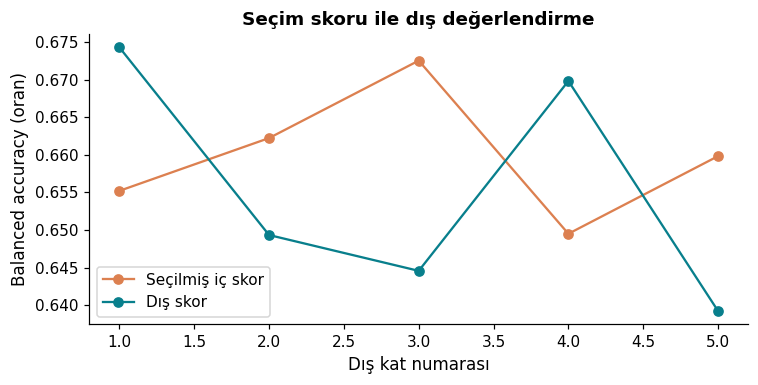

Şekil açıklaması: İç skor seçilen adayın geliştirme ölçümüdür; dış skor arama prosedürünün görülmemiş kayıtlardaki ölçümüdür.


In [31]:
grid={'model__max_depth':[3,5,8],'model__min_samples_leaf':[10,25,50]}
base_tree=make_pipe(DecisionTreeClassifier(random_state=SEED))
inner=StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED)
full_search=GridSearchCV(base_tree,grid,cv=inner,scoring='balanced_accuracy',n_jobs=N_JOBS).fit(X_dev,y_dev)
outer=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED+1)
nested_rows=[]
for k,(tr,va) in enumerate(outer.split(X_dev,y_dev),1):
    search=GridSearchCV(clone(base_tree),grid,cv=inner,scoring='balanced_accuracy',n_jobs=N_JOBS)
    search.fit(X_dev.iloc[tr],y_dev.iloc[tr])
    outer_score=balanced_accuracy_score(y_dev.iloc[va],search.predict(X_dev.iloc[va]))
    nested_rows.append({'dış_kat':k,'seçilmiş_iç_BA':search.best_score_,'dış_BA':outer_score,'parametre':str(search.best_params_)})
nested=pd.DataFrame(nested_rows)
display(nested)
print('Tüm geliştirmede best_score_:',round(full_search.best_score_,4))
print('İç içe dış skor:',pm(nested['dış_BA']))
print('Eşli iç-dış farkı:',pm(nested['seçilmiş_iç_BA']-nested['dış_BA']))
fig,ax=plt.subplots(figsize=(7,3.6))
ax.plot(nested['dış_kat'],nested['seçilmiş_iç_BA'],'o-',label='Seçilmiş iç skor',color='#dc8050')
ax.plot(nested['dış_kat'],nested['dış_BA'],'o-',label='Dış skor',color='#087f8c')
ax.set(xlabel='Dış kat numarası',ylabel='Balanced accuracy (oran)',title='Seçim skoru ile dış değerlendirme');ax.legend()
figure(fig,'nested_cv','İç skor seçilen adayın geliştirme ölçümüdür; dış skor arama prosedürünün görülmemiş kayıtlardaki ölçümüdür.')
RESULTS['nested']={'full_best':float(full_search.best_score_),'outer_mean':float(nested['dış_BA'].mean()),'outer_std':float(nested['dış_BA'].std(ddof=1))}

**Yorum:** Tüm geliştirmedeki `best_score_` 0.6562, dış değerlendirme 0.6555 ± 0.0156. Aynı dış katlardaki seçilmiş iç−dış farkı 0.0044 ± 0.0226. Arama maksimumu seçtiği için beklenen iyimserlik oluşabilir; tek veri setinde farkın her katta pozitif olması gerekmez. Bu deney karar ağacı ailesini inceler, 2.1'deki en iyi ailenin iç içe doğrulanmış skoru olarak sunulmaz. Dış kat skorlarına bağımsız t testi uygulanmadı.

### 2.4 Ayrılmış testte exact McNemar
En iyi iki model geliştirme skoruyla seçilip sabitlenmiştir. Şimdi her ikisi geliştirme verisinde eğitilir ve ayrılmış testte bir kez değerlendirilir. Exact McNemar, aynı kişide bir model doğruyken diğerinin yanlış olduğu iki sayıyı kullanır. Sıfır hipotezi eşit hata olasılığıdır; test BA/AUC eşitliğini doğrudan sınamaz. Anlamlılık eşiği önceden 0.05'tir.

In [32]:
top2=ranking[:2]
fitted={name:make_pipe(MODELS[name]).fit(X_dev,y_dev) for name in top2}
pred={name:pipe.predict(X_test) for name,pipe in fitted.items()}
holdout=[]
for name in top2:
    p=pred[name]; proba=fitted[name].predict_proba(X_test)[:,1]
    holdout.append({'Model':name,'BA':balanced_accuracy_score(y_test,p),'ROC_AUC':roc_auc_score(y_test,proba),
        'F1':f1_score(y_test,p),'precision':precision_score(y_test,p),'recall':recall_score(y_test,p)})
a=(pred[top2[0]]==y_test.to_numpy());b=(pred[top2[1]]==y_test.to_numpy())
both=int((a&b).sum()); only_a=int((a&~b).sum()); only_b=int((~a&b).sum()); neither=int((~a&~b).sum())
mcnemar_table=np.array([[both,only_a],[only_b,neither]])
p_value=1.0 if only_a+only_b==0 else float(binomtest(only_a,only_a+only_b,p=.5).pvalue)
display(pd.DataFrame(holdout).round(4))
display(pd.DataFrame(mcnemar_table,index=[top2[0]+' doğru',top2[0]+' yanlış'],columns=[top2[1]+' doğru',top2[1]+' yanlış']))
print('Exact McNemar p:',p_value,'| Uyuşmayan hata sayıları:',only_a,only_b)
print('Test örneklemi:',len(y_test),'| p<0.05:',p_value<.05)
RESULTS['holdout']=holdout; RESULTS['mcnemar']={'table':mcnemar_table.tolist(),'p':p_value,'models':top2}

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(


,Model,BA,ROC_AUC,F1,precision,recall
0,Gradyan artırma,0.6543,0.7211,0.6000,0.6527,0.5552
1,Lojistik,0.6534,0.7269,0.5813,0.6777,0.5089


,Lojistik doğru,Lojistik yanlış
Gradyan artırma doğru,744,75
Gradyan artırma yanlış,79,337


Exact McNemar p: 0.8090726851888611 | Uyuşmayan hata sayıları: 75 79
Test örneklemi: 1235 | p<0.05: False


**Yorum:** Gradyan artırma doğru, Lojistik yanlış olan 75 kişi; tersi 79 kişidir. Exact p = 0.8091. 0.05 düzeyinde toplam hata olasılığı farkı için yeterli kanıt bulunmadı; bu sonuç modellerin eşit olduğunu kanıtlamaz. Test skorları tek sabit ayrılmış örnekleme aittir; bunlara yapay standart sapma eklenmedi. Ana performans raporu 2.1'deki ortalama ± std'dir. McNemar sonucuna bakarak model değiştirilmedi.

### 2.5 Proje 2'ye aktarım ve sınırlamalar
Seçilen model geliştirme ortalama BA'sı en yüksek olan modeldir. Hattın kendisi, izin listesi, tohum, veri özeti ve bölme kimlikleri özel yerel dizine kaydedilir. Hedefe dayalı satır eleme dışında öğrenilen temizlik parametreleri tüm veriye fit edilmez; impute/kodlama/ölçekleme model hattında kalır. Proje 2 tam adillik ve alt grup analizi için bu hat üzerinden ilerleyebilir.

Geç dönem pozitif seçilimine duyarlılık için, yalnız 1 Nisan 2014 ve öncesindeki geliştirme kayıtlarında, sabit seçilmiş model 5 kat ÇD ile yeniden değerlendirilir. Bu başka bir örneklemin ölçümüdür; yöntem farkına ilişkin kontrollü bir deney değildir.

In [33]:
best_name=ranking[0]; best_pipe=fitted[best_name]
early_dev=(screen.iloc[dev_idx]<=cutoff).to_numpy()
sensitivity=cross_val_score(make_pipe(MODELS[best_name]),X_dev.loc[early_dev],y_dev.loc[early_dev],
    cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED),scoring='balanced_accuracy',n_jobs=N_JOBS)
print('Erken dönem geliştirme kayıtları:',int(early_dev.sum()),'| BA:',pm(sensitivity))
perm=permutation_importance(best_pipe,X_dev,y_dev,scoring='balanced_accuracy',n_repeats=5,random_state=SEED,n_jobs=N_JOBS)
importance=pd.DataFrame({'ozellik':FEATURES,'ortalama_BA_azalmasi':perm.importances_mean,'std':perm.importances_std}).sort_values('ortalama_BA_azalmasi',ascending=False)
display(importance.round(4))
print('Önem analizi eğitim/geliştirme verisinde betimseldir, bağımsız önem tahmini değildir.')
import joblib
joblib.dump(best_pipe,PRIVATE/'p1_hat.joblib')
clean=X.copy(); clean['race_audit']=df.race; clean['two_year_recid']=y
clean.to_csv(PRIVATE/'p1_temiz_veri.csv',index=False)
np.savez(PRIVATE/'p1_bolmeler.npz',development=dev_idx,test=test_idx)
protocol={'seed':SEED,'features':FEATURES,'selected_model':best_name,'split':'stratified 80/20',
    'cv':'5-fold x 3 repeats on development','primary_metric':'balanced_accuracy','data_sha256':sha,
    'cohort_filter':'ProPublica canonical 6172','threshold':.5,'race_in_model':False}
(RUN/'protokol.json').write_text(json.dumps(protocol,ensure_ascii=False,indent=2),encoding='utf-8')
RESULTS['best']=best_name;RESULTS['importance']=importance.to_dict('records')
RESULTS['sensitivity']={'n':int(early_dev.sum()),'mean':float(sensitivity.mean()),'std':float(sensitivity.std(ddof=1))}

Erken dönem geliştirme kayıtları: 4228 | BA: 0.6480 ± 0.0087


,ozellik,ortalama_BA_azalmasi,std
4,priors_count,0.1340,0.0059
0,age_at_screen,0.0785,0.0050
7,c_charge_desc,0.0314,0.0041
6,c_charge_degree,0.0070,0.0011
5,sex,0.0056,0.0014
3,juv_other_count,0.0031,0.0011
2,juv_misd_count,0.0012,0.0007
1,juv_fel_count,0.0001,0.0005


Önem analizi eğitim/geliştirme verisinde betimseldir, bağımsız önem tahmini değildir.


**Yorum:** Aktarılan Gradyan artırma modeli için ana BA 0.6632 ± 0.0175; erken dönem duyarlılık sonucu 0.6480 ± 0.0087. Fark kohortun ve örneklem boyutunun değişimini de içerir. Aynı veride seçim yanlılığını tamamen düzeltmez, ancak raporlanan başarımın veri oluşturma kararına duyarlı olduğunu görünür kılar. Permütasyon önemi aşağıdaki kurallarla yorum amaçlı karşılaştırılır; geliştirme üzerinde hesaplandığı için eğitim iyimserliği olabilir. Bu önem değeri nedensel etki değildir. Kaydedilen model yalnız geliştirmede fit edilmiştir; test kayıtlarıyla sonradan yeniden fit edilmemiştir. Temiz veri ve model GitHub paketinin dışında tutulur, yeniden çalıştırmayla üretilir.

# Bölüm 3 Veri küpü ve birliktelik analizi
**Makale okuma notu:** Wu, Chen ve Han (2010), ilgi ölçütlerinin aynı örüntüyü farklı sıralayabildiğini ve marjinal sıklıkların etkisini tartışır. Güven, sonucun genel yaygınlığından etkilenir; lift nadir olaylarda yüksek görünebilir. Kulczynski iki koşullu olasılığı simetrik birleştirir; tek başına bir nedensellik veya adillik ölçüsü değildir. Bu nedenle aşağıda destek/adet, güven, lift, Kulczynski ve dengesizlik oranı birlikte raporlanır.

### 3.1 Üç boyutlu veri küpü ve Simpson incelemesi
Olgu kişi kaydı, ölçüler kişi sayısı ve pozitif etiket sayısı/oranı, boyutlar yaş grubu, cinsiyet ve ırksal grup olarak tanımlanır. Analiz geliştirme verisindedir. Oranların ortalaması alınmaz; önce paylar ve paydalar toplanır. Irksal alan betimsel denetim içindir; normatif veya biyolojik açıklama değildir.

Drill-down: yaş × cinsiyet × ırksal grup


n  positive    rate
age_band sex    race                                    
25 altı  Female African-American   171        73  0.4269
                Caucasian           95        31  0.3263
                Hispanic            15         3  0.2000
                Other               14         3  0.2143
         Male   African-American   814       511  0.6278
                Asian                5         2  0.4000
                Caucasian          348       174  0.5000
                Hispanic           111        50  0.4505
                Native American      3         2  0.6667
                Other               68        39  0.5735
25–44    Female African-American   218        77  0.3532
                Asian                2         1  0.5000
                Caucasian          201        84  0.4179
                Hispanic            38        11  0.2895
                Native American      2         2  1.0000
                Other               27         7  0.2593
         Male   African-American  1026       534  0.5205
                Asian               13         2  0.1538
                Caucasian          620       264  0.4258
                Hispanic           179        62  0.3464
                Native American      4         0  0.0000
                Other              117        43  0.3675
45+      Female African-American    44        10  0.2273
                Caucasian          100        23  0.2300
                Hispanic            11         2  0.1818
                Other                4         1  0.2500
         Male   African-American   261       119  0.4559
                Asian                4         2  0.5000
                Caucasian          312        85  0.2724
                Hispanic            61        16  0.2623
                Native American      1         1  1.0000
                Other               48        13  0.2708

Roll-up: cinsiyet × ırksal grup


n  positive    rate
sex    race                                    
Female African-American   433       160  0.3695
       Asian                2         1  0.5000
       Caucasian          396       138  0.3485
       Hispanic            64        16  0.2500
       Native American      2         2  1.0000
       Other               45        11  0.2444
Male   African-American  2101      1164  0.5540
       Asian               22         6  0.2727
       Caucasian         1280       523  0.4086
       Hispanic           351       128  0.3647
       Native American      8         3  0.3750
       Other              233        95  0.4077

sex,Female,Male
age_band,,
25 altı,0.3729,0.5767
25–44,0.3730,0.4620
45+,0.2264,0.3435


,size,mean
race,,
African-American,2534,0.5225
Caucasian,1676,0.3944


n_en_kucuk  oran_farki  yeterli_n  ters_yon
age_band sex                                                
25 altı  Female          95      0.1006       True     False
         Male           348      0.1278       True     False
25–44    Female         201     -0.0647       True      True
         Male           620      0.0947       True     False
45+      Female          44     -0.0027       True      True
         Male           261      0.1835       True     False

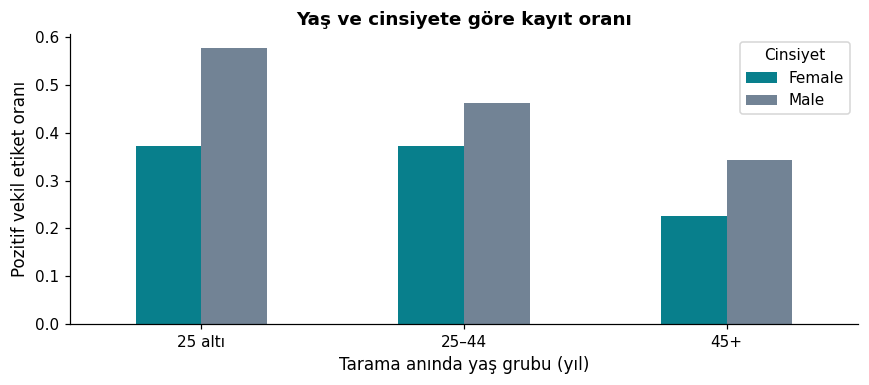

Şekil açıklaması: Alt gruplardaki farklar kayıt ve örneklem süreçlerini de yansıtır; neden-sonuç ilişkisi kurulamaz.


In [34]:
cube_data=df.iloc[dev_idx][['sex','race','two_year_recid','age_at_screen']].copy()
cube_data['age_band']=pd.cut(cube_data.age_at_screen,bins=[0,25,45,np.inf],right=False,labels=['25 altı','25–44','45+'])
cube=cube_data.groupby(['age_band','sex','race'],observed=True).two_year_recid.agg(n='size',positive='sum')
cube['rate']=cube.positive/cube.n
roll=cube.groupby(level=['sex','race'])[['n','positive']].sum();roll['rate']=roll.positive/roll.n
print('Drill-down: yaş × cinsiyet × ırksal grup');display(cube.round(4))
print('Roll-up: cinsiyet × ırksal grup');display(roll.round(4))
pivot=pd.pivot_table(cube_data,index='age_band',columns='sex',values='two_year_recid',aggfunc='mean',observed=True)
display(pivot.round(4))
pair=cube_data[cube_data.race.isin(['African-American','Caucasian'])]
overall=pair.groupby('race').two_year_recid.agg(['size','mean'])
strata=pair.groupby(['age_band','sex','race'],observed=True).two_year_recid.agg(['size','mean']).reset_index()
st_mean=strata.pivot(index=['age_band','sex'],columns='race',values='mean')
st_n=strata.pivot(index=['age_band','sex'],columns='race',values='size')
valid=st_n.min(axis=1)>=30
diff=st_mean['African-American']-st_mean['Caucasian']
overall_diff=float(overall.loc['African-American','mean']-overall.loc['Caucasian','mean'])
reversal=(np.sign(diff[valid])!=np.sign(overall_diff))
simpson=pd.DataFrame({'n_en_kucuk':st_n.min(axis=1),'oran_farki':diff,'yeterli_n':valid,'ters_yon':reversal.reindex(diff.index,fill_value=False)})
display(overall.round(4));display(simpson.round(4))
fig,ax=plt.subplots(figsize=(8,3.6))
pivot.plot(kind='bar',ax=ax,color=['#087f8c','#728395'],rot=0)
ax.set(xlabel='Tarama anında yaş grubu (yıl)',ylabel='Pozitif vekil etiket oranı',title='Yaş ve cinsiyete göre kayıt oranı');ax.legend(title='Cinsiyet')
figure(fig,'veri_kupu','Alt gruplardaki farklar kayıt ve örneklem süreçlerini de yansıtır; neden-sonuç ilişkisi kurulamaz.')
RESULTS['simpson']={'overall_diff':overall_diff,'valid_strata':int(valid.sum()),'reversal_count':int(reversal.sum())}

**Yorum:** İki büyük ırksal grubun toplam pozitif oran farkı +0.1281. Her iki grupta en az 30 kişi bulunan 6 yaş×cinsiyet tabakasından 2 tanesinde işaret toplamla ters yönde bulundu. Bazı tabakalarda yön değişimi vardır; bu durum tek başına tüm tabakalarda Simpson paradoksu bulunduğunu göstermez. Paradoks bulunmaması da geçerli sonuçtur. Küçük grupları kesin yargılarla yorumlamamak için sayılar birlikte verilmiştir.

### 3.2 Birliktelik B seçeneği ve ayrıklaştırma
Bir satır bir kişi olduğu için **B seçeneği** kullanılır. Kayıtlar özellik=değer öğelerinden oluşan işlem sayılır. Model ve kural analizi aynı kişilerden gelir, yeni veri setine geçilmez. Sayısal sınırlar verinin hedefinden öğrenilmez: yaş 25 ve 45, önceki kayıt sayısı 0/1–2/3–5/6+, toplam çocukluk kayıt sayısı 0/1+. Cinsiyet, isnat derecesi ve hedef de nominal öğedir. Çok sayıda sıfır içeren sayımlarda 0 ayrı tutulur. Önceki kayıtların varlığı sonraki olayın nedeni diye yorumlanmaz.

Destek alt sınırı 0.03, güven 0.60, en fazla 2 öncül öğe olarak önceden belirlenir. Destek gerçek tamsayı adede çevrilir ve Weka ile aynı destek sınırında kontrol edilir. Yalnız hedef=1 sonucu olan kurallar üretilir; bütün olası kuralları belleğe almak gerekmez.

In [35]:
from mlxtend.frequent_patterns import fpgrowth
from mlxtend.preprocessing import TransactionEncoder
transactions=pd.DataFrame(index=X_dev.index)
transactions['age']=pd.cut(X_dev.age_at_screen,[0,25,45,np.inf],right=False,labels=['under25','25_44','45_plus']).astype(str)
transactions['priors']=pd.cut(X_dev.priors_count,[-1,0,2,5,np.inf],labels=['0','1_2','3_5','6_plus']).astype(str)
transactions['juvenile']=np.where(X_dev[['juv_fel_count','juv_misd_count','juv_other_count']].sum(axis=1)>0,'1_plus','0')
transactions['sex']=X_dev.sex.astype(str)
transactions['degree']=X_dev.c_charge_degree.astype(str)
transactions['target']=y_dev.astype(str)
baskets=[[f'{c}={v}' for c,v in zip(transactions.columns,row)] for row in transactions.itertuples(index=False,name=None)]
te=TransactionEncoder(); binary=pd.DataFrame(te.fit_transform(baskets),columns=te.columns_,index=transactions.index)
MIN_SUPPORT=.03;MIN_CONF=.60
# Weka CAR sayacında kesirli N*s için round(N*s+0.5), yani ceil uygulanır.
MIN_COUNT=int(np.ceil(MIN_SUPPORT*len(binary)))
EFFECTIVE_SUPPORT=(MIN_COUNT-1e-9)/len(binary)
freq=fpgrowth(binary,min_support=EFFECTIVE_SUPPORT,use_colnames=True,max_len=3)
support_map={frozenset(items):float(s) for s,items in zip(freq.support,freq.itemsets)}
target=frozenset(['target=1']); sb=float(binary['target=1'].mean())
rules_list=[]
for items,sab in support_map.items():
    if not target.issubset(items) or len(items)<2: continue
    antecedent=items-target
    if len(antecedent)>2: continue
    sa=support_map[antecedent];confidence=sab/sa
    if confidence+1e-12<MIN_CONF: continue
    reverse=sab/sb
    rules_list.append({'onculler':' & '.join(sorted(antecedent)),'sonuc':'target=1','oncul_boyutu':len(antecedent),
        'ortak_adet':int(round(sab*len(binary))),'oncul_adet':int(round(sa*len(binary))),
        'support':sab,'confidence':confidence,'lift':confidence/sb,'kulczynski':.5*(confidence+reverse),
        'IR':abs(sa-sb)/(sa+sb-sab),'_items':antecedent})
rules=pd.DataFrame(rules_list)
assert len(rules)>0
for metric in ['confidence','lift','kulczynski']:
    print('\nİlk 10, sıralama:',metric)
    display(rules.sort_values([metric,'support'],ascending=False).drop(columns='_items').head(10).round(4))
rules.drop(columns='_items').to_csv(RUN/'hedef_kurallari.csv',index=False)
print('İşlem sayısı:',len(binary),'| Öğeler:',binary.shape[1],'| Sık kümeler:',len(freq),'| Hedef kuralları:',len(rules),'| min adet:',MIN_COUNT)


İlk 10, sıralama: confidence


,onculler,sonuc,oncul_boyutu,ortak_adet,oncul_adet,support,confidence,lift,kulczynski,IR
6,juvenile=1_plus & priors=6_plus,target=1,2,226,293,0.0458,0.7713,1.6947,0.4360,0.8444
11,age=under25 & priors=3_5,target=1,2,188,258,0.0381,0.7287,1.6010,0.4062,0.8584
2,degree=F & priors=6_plus,target=1,2,549,757,0.1112,0.7252,1.5934,0.4848,0.6069
3,age=25_44 & priors=6_plus,target=1,2,443,616,0.0897,0.7192,1.5801,0.4582,0.6740
1,priors=6_plus & sex=Male,target=1,2,617,865,0.1250,0.7133,1.5672,0.4939,0.5539
8,degree=F & juvenile=1_plus,target=1,2,351,493,0.0711,0.7120,1.5643,0.4341,0.7342
0,priors=6_plus,target=1,1,689,971,0.1396,0.7096,1.5591,0.5081,0.5045
7,juvenile=1_plus & sex=Male,target=1,2,429,605,0.0869,0.7091,1.5580,0.4500,0.6777
10,age=under25 & juvenile=1_plus,target=1,2,274,394,0.0555,0.6954,1.5280,0.4087,0.7828
5,juvenile=1_plus,target=1,1,464,672,0.0940,0.6905,1.5171,0.4485,0.6415



İlk 10, sıralama: lift


,onculler,sonuc,oncul_boyutu,ortak_adet,oncul_adet,support,confidence,lift,kulczynski,IR
6,juvenile=1_plus & priors=6_plus,target=1,2,226,293,0.0458,0.7713,1.6947,0.4360,0.8444
11,age=under25 & priors=3_5,target=1,2,188,258,0.0381,0.7287,1.6010,0.4062,0.8584
2,degree=F & priors=6_plus,target=1,2,549,757,0.1112,0.7252,1.5934,0.4848,0.6069
3,age=25_44 & priors=6_plus,target=1,2,443,616,0.0897,0.7192,1.5801,0.4582,0.6740
1,priors=6_plus & sex=Male,target=1,2,617,865,0.1250,0.7133,1.5672,0.4939,0.5539
8,degree=F & juvenile=1_plus,target=1,2,351,493,0.0711,0.7120,1.5643,0.4341,0.7342
0,priors=6_plus,target=1,1,689,971,0.1396,0.7096,1.5591,0.5081,0.5045
7,juvenile=1_plus & sex=Male,target=1,2,429,605,0.0869,0.7091,1.5580,0.4500,0.6777
10,age=under25 & juvenile=1_plus,target=1,2,274,394,0.0555,0.6954,1.5280,0.4087,0.7828
5,juvenile=1_plus,target=1,1,464,672,0.0940,0.6905,1.5171,0.4485,0.6415



İlk 10, sıralama: kulczynski


,onculler,sonuc,oncul_boyutu,ortak_adet,oncul_adet,support,confidence,lift,kulczynski,IR
0,priors=6_plus,target=1,1,689,971,0.1396,0.7096,1.5591,0.5081,0.5045
1,priors=6_plus & sex=Male,target=1,2,617,865,0.1250,0.7133,1.5672,0.4939,0.5539
2,degree=F & priors=6_plus,target=1,2,549,757,0.1112,0.7252,1.5934,0.4848,0.6069
3,age=25_44 & priors=6_plus,target=1,2,443,616,0.0897,0.7192,1.5801,0.4582,0.6740
7,juvenile=1_plus & sex=Male,target=1,2,429,605,0.0869,0.7091,1.5580,0.4500,0.6777
5,juvenile=1_plus,target=1,1,464,672,0.0940,0.6905,1.5171,0.4485,0.6415
4,juvenile=0 & priors=6_plus,target=1,2,463,678,0.0938,0.6829,1.5004,0.4445,0.6373
6,juvenile=1_plus & priors=6_plus,target=1,2,226,293,0.0458,0.7713,1.6947,0.4360,0.8444
8,degree=F & juvenile=1_plus,target=1,2,351,493,0.0711,0.7120,1.5643,0.4341,0.7342
10,age=under25 & juvenile=1_plus,target=1,2,274,394,0.0555,0.6954,1.5280,0.4087,0.7828


İşlem sayısı: 4937 | Öğeler: 15 | Sık kümeler: 287 | Hedef kuralları: 12 | min adet: 149


**Yorum:** 4937 işlemde 12 hedefe yönelik kural bulundu. Destek en az 149 ortak kayıt olarak uygulandı. B seçeneğinde üç destek seviyesinde Apriori/FP-Growth süre karşılaştırması ve null işlem deneyi zorunlu değildir; A seçeneğinin görevleri karıştırılmadı. `max_len=3`, hedefle birlikte en fazla iki öncül anlamına gelir. Çok sık “yokluk” öğeleri çok uzun kurallar üretebildiği için sade kurulum kullanıldı. Her kural bu kohortun betimsel ilişkisidir.

### 3.3 Nadir kategori ilgi ölçütleri ve üç kuralın yorumu
Güven ile lift bu alt kümede aynı tek hedefe bağlı olduğundan, lift=güven/P(hedef) ve sıralamaları aynıdır. Kulczynski, hedefi kapsama oranını da hesaba kattığından yaygın bir öncülü daha üste taşıyabilir. En yüksek lift'li bir kural ve en yüksek Kulczynski'li bir kural bu nedenle farklı olabilir.

In [36]:
rare_candidates=rules[rules['oncul_adet']/len(binary)<.10].sort_values('lift',ascending=False)
common_candidates=rules[rules['oncul_adet']/len(binary)>.15].sort_values('kulczynski',ascending=False)
comparison=pd.concat([rare_candidates.head(1).assign(tur='Nadir öncül (<%10)'),common_candidates.head(1).assign(tur='Daha yaygın öncül (>%15)')])
display(comparison.drop(columns='_items').round(4))
# Gerçek nadir kategori: çocukluk ağır suç kaydı var (juv_fel_count>0).
# Ana .03 destek eşiğinin altında da kalabilen bu kural ayrı betimsel tanı olarak gösterilir.
rare_mask=X_dev.juv_fel_count.gt(0)
rare_sa=float(rare_mask.mean());rare_sab=float((rare_mask & y_dev.eq(1)).mean())
rare_conf=rare_sab/rare_sa
rare_category={'kategori':'juv_fel_count=1_plus','oncul_adet':int(rare_mask.sum()),
    'ortak_adet':int((rare_mask & y_dev.eq(1)).sum()),'oncul_orani':rare_sa,'support':rare_sab,
    'confidence':rare_conf,'lift':rare_conf/sb,'kulczynski':.5*(rare_conf+rare_sab/sb),
    'IR':abs(rare_sa-sb)/(rare_sa+sb-rare_sab)}
display(pd.DataFrame([rare_category]).round(4))
chosen=rules.sort_values(['lift','support'],ascending=False).drop_duplicates('onculler').head(3)
display(chosen.drop(columns='_items').round(4))
top_features=importance.ozellik.head(3).tolist()
print('Modelde betimsel ilk 3 önem:',top_features)
for i,row in enumerate(chosen.itertuples(),1):
    print(f'Kural {i}: {row.onculler} => target=1; ortak n={row.ortak_adet}; '
        f'güven={row.confidence:.3f}; lift={row.lift:.3f}; Kulczynski={row.kulczynski:.3f}')
RESULTS['rules_count']=len(rules);RESULTS['top_rules']=chosen.drop(columns='_items').to_dict('records')
RESULTS['rare_rule_comparison']=comparison.drop(columns='_items').to_dict('records')
RESULTS['rare_category']=rare_category

,onculler,sonuc,oncul_boyutu,ortak_adet,oncul_adet,support,confidence,lift,kulczynski,IR,tur
6,juvenile=1_plus & priors=6_plus,target=1,2,226,293,0.0458,0.7713,1.6947,0.4360,0.8444,Nadir öncül (<%10)
0,priors=6_plus,target=1,1,689,971,0.1396,0.7096,1.5591,0.5081,0.5045,Daha yaygın öncül (>%15)


,kategori,oncul_adet,ortak_adet,oncul_orani,support,confidence,lift,kulczynski,IR
0,juv_fel_count=1_plus,167,117,0.0338,0.0237,0.7006,1.5393,0.3763,0.9055


,onculler,sonuc,oncul_boyutu,ortak_adet,oncul_adet,support,confidence,lift,kulczynski,IR
6,juvenile=1_plus & priors=6_plus,target=1,2,226,293,0.0458,0.7713,1.6947,0.4360,0.8444
11,age=under25 & priors=3_5,target=1,2,188,258,0.0381,0.7287,1.6010,0.4062,0.8584
2,degree=F & priors=6_plus,target=1,2,549,757,0.1112,0.7252,1.5934,0.4848,0.6069


Modelde betimsel ilk 3 önem: ['priors_count', 'age_at_screen', 'c_charge_desc']
Kural 1: juvenile=1_plus & priors=6_plus => target=1; ortak n=226; güven=0.771; lift=1.695; Kulczynski=0.436
Kural 2: age=under25 & priors=3_5 => target=1; ortak n=188; güven=0.729; lift=1.601; Kulczynski=0.406
Kural 3: degree=F & priors=6_plus => target=1; ortak n=549; güven=0.725; lift=1.593; Kulczynski=0.485


**Yorum:** İlk kural **juvenile=1_plus & priors=6_plus**, hedefle birlikte 226 kişide gözlendi; güven 0.771, lift 1.695. Çocukluk kayıtları ile 6+ önceki kayıt birlikteyse kayıt oranı kohort ortalamasının üzerindedir; kişi hakkında kesin hüküm üretmez. İkinci kural **age=under25 & priors=3_5**, 188 ortak kayda dayanır; genç yaş ve 3–5 önceki kaydın birleşimini gösterir. Üçüncü kural **degree=F & priors=6_plus**, 549 ortak kayıtla ağır isnat derecesi ve 6+ önceki kaydın birlikteliğidir. İsnat mahkûmiyet veya suçluluk kanıtı değildir; daha dar öncül her zaman daha yararlı değildir.

Gerçek nadir kategori `juv_fel_count>0`, geliştirmede 167 kişide (%3.38) bulunur. Bu kategori→hedef kuralı için lift 1.539, Kulczynski 0.376'dir. Ortak destek 0.0237 olduğu için ana .03 eşik listesinden ayrı tanı olarak gösterilir; eşik sonuca göre düşürülmedi. Bu örnek nadir bir kategorinin yüksek lift ve daha sınırlı simetrik kapsama değerini somutlaştırır.

Modelde öne çıkan priors_count, age_at_screen, c_charge_desc alanlarıyla, kurallardaki yaş ve geçmiş kayıt öğeleri ortak bir ilişki taşıyabilir. Kural sınırları alan bilgisiyle sabittir, model daha ince eşikler öğrenir. Nadir öncül yüksek lift'e rağmen hedef pozitiflerin küçük bölümünü kapsayabilir; Kulczynski bu kapsamı da hesaba katar. Kulczynski=0.5 evrensel bağımsızlık sınırı değildir, çünkü marjinal sıklıklar değişir. Küçük destekli kuralın yüksek lift'i sağlamlık veya nedensellik kanıtı sayılmaz. Tam adillik değerlendirmesi Proje 2 kapsamındadır.

### 3.4 Weka Apriori ile aynı eşiklerde kontrol
Ayrıklaştırılmış aynı geliştirme tablosu nominal ARFF olarak yazılır. `-A -c last` sınıf kurallarını, `-M 0.03` alt destek ve `-C 0.60` güveni belirler. `-N 2147483647` Weka CAR kaynak kodunda doğrudan alt destekten başlatan özel yoldur; `-U 1.0` desteği yüksek kuralları budamayı engeller. Üst ve alt sınırı .03'e eşitlemek bu sürümde .03 üzerindeki kuralları siler; bu nedenle kullanılmaz. `-Z` kullanılmaz; sıfır kategorileri eksik değildir. Weka tüm uzunlukları arayabilir; karşılaştırmada sonucu 1 ve öncülü en fazla iki olan ortak kapsam alınır. Kurallar metinle değil, öncül öğe kümesiyle eşleştirilir.

In [37]:
assoc_arff=PRIVATE/'compas_ayrik.arff'
write_arff(transactions,assoc_arff,'compas_discretized')
command=java_cmd+['weka.associations.Apriori','-t',str(assoc_arff),'-A','-c','last',
    '-N','2147483647','-T','0','-C',str(MIN_CONF),'-U','1.0','-M',str(MIN_SUPPORT)]
result=subprocess.run(command,capture_output=True,text=True,encoding='utf-8',errors='replace',timeout=240)
assert result.returncode==0 and 'Best rules found' in result.stdout, result.stdout+result.stderr
weka_apriori=result.stdout
(RUN/'weka_Apriori.txt').write_text(weka_apriori,encoding='utf-8')
print(weka_apriori)
weka_rules={}
pattern=re.compile(r'([^\s=]+)=([^\s]+)')
for line in weka_apriori.splitlines():
    if '==>' not in line:continue
    left,right=line.split('==>',1)
    ant=frozenset(f'{k}={v}' for k,v in pattern.findall(left))
    con=pattern.findall(right)
    if not con or con[0]!=('target','1') or not 1<=len(ant)<=2:continue
    cnt=re.search(r'target=1\s+(\d+)',right)
    conf=re.search(r'conf:\(([^)]+)\)',right)
    if cnt: weka_rules[ant]={'adet':int(cnt.group(1)),'confidence_yuvarlanmis':float(conf.group(1)) if conf else None}
python_rules={r['_items']:r for r in rules.to_dict('records')}
matched=set(python_rules)&set(weka_rules)
count_mismatch=[sorted(k) for k in matched if python_rules[k]['ortak_adet']!=weka_rules[k]['adet']]
only_python=[sorted(k) for k in set(python_rules)-set(weka_rules)]
only_weka=[sorted(k) for k in set(weka_rules)-set(python_rules)]
print('Python ortak kapsam:',len(python_rules),'| Weka ortak kapsam:',len(weka_rules),'| Eşleşen:',len(matched))
print('Adet farkları:',count_mismatch,'| Yalnız Python:',only_python,'| Yalnız Weka:',only_weka)
assert len(matched)>0, 'Weka çıktı ayrıştırmasını inceleyin.'
assert not count_mismatch and not only_python and not only_weka, 'Bağımsız kural kontrolünde fark var; yorumlamadan inceleyin.'
RESULTS['weka_rules']={'python':len(python_rules),'weka':len(weka_rules),'matched':len(matched),'count_mismatches':len(count_mismatch)}

[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate

Apriori

Minimum support: 0.03 (148 instances)
Minimum metric <confidence>: 0.6
Number of cycles performed: 1

Generated sets of large itemsets:

Size of set of large itemsets L(1): 26

Size of set of large itemsets L(2): 92

Size of set of large itemsets L(3): 117

Size of set of large itemsets L(4): 50

Size of set of large itemsets L(5): 5

Best rules found:

         1. priors=0 juvenile=0 sex=Female degree=M 229 ==> target=0 195    conf:(0.85)
         2. priors=0 sex=Female degree=M 233 ==> target=0 196    conf:(0.84)
         3. age=45_plus priors=0 284 ==> target=0 238    conf:(0.84)
         4. age=45_plus priors=0 juvenile=0 284 ==> target=0 238    con

**Yorum:** Aynı veri, destek adedi, güven ve öncül uzunluğunda Python 12, Weka 12 kural üretti; 12 kural eşleşti, ortak kayıt sayısında fark 0. Böylece bağımsız uygulama kontrolü yalnız benzer bir ekran görüntüsüne dayanmaz. Weka güveni iki ondalığa yuvarlayabildiğinden asıl eşleştirme destek adetleri ve öncül kümeleriyle yapıldı. Weka'nın daha uzun kuralları bu sayıya dahil değildir. Weka metni destek için 148 instances yazsa da CAR iç sayacı kesirli N×s değerini yukarı yuvarlayarak 149 uygular; eşleştirme kodu bu iç eşikle yapılmıştır.

## Varsayım defteri
- **Tahmin anı:** İndeks COMPAS taraması. Sonradan oluşan takip, tahliye, olay ve değerlendirme bilgileri çıkarıldı. Karar Kaufman vd. sızıntı çerçevesine dayanır.
- **Kohort:** Resmi ProPublica notebookunun kanonik filtresi kullanıldı. Bu bir operasyonel örneklem varsayımıdır, tüm topluma genellenmez.
- **Yaş:** Ham yaş yerine tarama tarihinden türetildi. Kaynak zaman referansındaki uyumsuzluk önlendi.
- **Kimlik:** name+dob tekilliği yalnız yerelde kontrol edildi; bu alanlar modelde veya çıktılarda gösterilmedi. Aynı isim aynı kişi sayılmadı.
- **Kişisel veri:** Ham dosya, ARFF, temiz kişi tablosu ve kayıt sıra indeksleri GitHub'a konmaz. `.gitignore` ve ayrı özel çıktı dizini kullanılır.
- **Bölme:** %20 katmanlı test ayrıldı. Bütün yöntem geliştirme verisinde sabitlendi; testteki iki model sonucu seçim için kullanılmadı.
- **Çapraz doğrulama:** 5 kat × 3 tekrar ortak katlar. Ön işleme yalnız eğitim katında öğrenildi. Standart sapma kat değişkenliğidir.
- **Ölçüt:** BA ana ölçüt, ROC-AUC ve pozitif sınıf ölçütleri ikincil. Adli yanlış pozitif/negatif maliyetleri bu veriden güvenilir şekilde belirlenmediği için maliyet optimize edilmedi.
- **Kodlama:** Nadir OHE eşik 20; TE deneyinde iç 5 kat. Yanlış kurulumlar final hatta taşınmadı.
- **Eksiklik:** Mekanizmalar gözlemsel veriden kanıtlanamaz. Sonuç alanlarındaki yapısal eksiklik güvenli girdiye dönüştürülmedi.
- **Hiperparametre:** Ana modeller sınırlı ve sabit. Ayrı karar ağacı araması için iç3/dış5 kat. Bir veri setindeki farkın yönü genellenmedi.
- **İstatistik:** Exact McNemar aynı bağımsız test kayıtlarındaki toplam hata farkını sınar. CV katlarına naif t testi yapılmadı. Bu karar Dietterich'e dayanır.
- **Kurallar:** B seçeneği, sabit domain sınırları, destek .03, güven .60, en fazla iki öncül. Güven/lift/Kulczynski birlikte okunur; Wu vd. ölçüt tartışmasına dayanır.
- **Küp:** Sayımlar toplandıktan sonra oran hesaplandı; ortalamaların ortalaması alınmadı. Küçük tabakalar için n≥30 şartı betimsel kontroldür.
- **Adillik:** race X dışında, sex X içinde. Irkı çıkarmak adillik sağlamaz; vekil özellikler kalabilir. Grup farkları kayıt ve seçim mekanizmalarını içerir.
- **Sınırlamalar:** Tek ilçe, eski kayıtlar, vekil hedef, pozitif seçilimi ve lisans belirsizliği vardır. Erken dönem duyarlılığı seçilim problemini tamamen çözmez.

## Katkı ve yapay zekâ beyanı
**Bireysel çalışma:** Proje 1 Bölüm 1.1–3.4 kapsamındaki çalışmayı bireysel olarak yürüttüm. Defteri 15 Kasım 2026'da Colab üzerinde çalıştırdım; çıktıları kontrol edip dışa aktardım. Sunumu kendi anlatımımla kaydettim, bölümleri birleştirerek 17 dakika 14 saniyelik [sunum videosunu](https://drive.google.com/file/d/1JcfYduPzdD2myVyBZvJINpqfuLIE4u_0/view?usp=sharing) Google Drive'da paylaştım. Bağlantıyı gizli pencerede açarak erişimi kontrol ettim. Proje dosyalarını [GitHub deposuna](https://github.com/ygoktepe/BIL545-Proje1-COMPAS) yükledim.

**Yapay zekâ kullanımı:** Bu projede OpenAI Codex'ten kaynak araştırması, kod oluşturma ve hata giderme, analiz sonuçlarını yorumlama ve sunum metni hazırlama aşamalarında destek aldım. Defteri Colab'da çalıştırdım, çıktıları kontrol ettim ve sunumu kendi anlatımımla kaydettim.

## Kaynaklar
1. ProPublica COMPAS veri ve analiz deposu. https://github.com/propublica/compas-analysis (erişim 14 Kasım 2026).
2. Larson, Mattu, Kirchner ve Angwin (2016). How We Analyzed the COMPAS Recidivism Algorithm. https://www.propublica.org/article/how-we-analyzed-the-compas-recidivism-algorithm
3. Kaufman, Rosset, Perlich ve Stitelman (2012). Leakage in Data Mining. ACM TKDD 6(4). https://doi.org/10.1145/2382577.2382579
4. Dietterich (1998). Approximate Statistical Tests for Comparing Supervised Classification Learning Algorithms. Neural Computation 10(7), 1895–1923. https://doi.org/10.1162/089976698300017197
5. Wu, Chen ve Han (2010). Re-examination of Interestingness Measures in Pattern Mining. DMKD 21, 371–397. https://doi.org/10.1007/s10618-009-0161-2
6. Barenstein (2019). ProPublica's COMPAS Data Revisited. https://arxiv.org/abs/1906.04711
7. scikit-learn TargetEncoder ve cross-fitting. https://scikit-learn.org/1.6/modules/generated/sklearn.preprocessing.TargetEncoder.html
8. Weka 3.8 API. https://weka.sourceforge.io/doc.stable/weka/associations/Apriori.html
9. BIL545 Proje 1 ve Proje 2 Yönergesi, Değerlendirme Esasları, README ve notebook şablonu (20261007); Hafta 2–7 ders materyalleri; 29 Ekim ve 4 Kasım 2026 STIX duyuruları. Oyunlar proje kapsamına alınmadı.

In [38]:
RESULTS['encoding']={k:{'mean':float(v.mean()),'std':float(v.std(ddof=1))} for k,v in encoding_scores.items()}
RESULTS['leakage']={k:{'mean':float(v.mean()),'std':float(v.std(ddof=1))} for k,v in leak_scores.items()}
RESULTS['indicator']={k:{'mean':float(v.mean()),'std':float(v.std(ddof=1))} for k,v in indicator_scores.items()}
RESULTS['protocol']=protocol
(RUN/'sonuclar.json').write_text(json.dumps(RESULTS,ensure_ascii=False,indent=2),encoding='utf-8')
print('Tamamlandı. Bütün yazılı yanıtlar bu defterdedir. Kişi düzeyinde çıktılar yalnız yerel özel dizindedir.')
print('GitHub için README + bu çalıştırılmış notebook yeterlidir; video bağlantısı öğrenci tarafından eklenmelidir.')

Tamamlandı. Bütün yazılı yanıtlar bu defterdedir. Kişi düzeyinde çıktılar yalnız yerel özel dizindedir.
GitHub için README + bu çalıştırılmış notebook yeterlidir; video bağlantısı öğrenci tarafından eklenmelidir.
